# Воспроизведение классификации поверхности по IMU

[Статья Wassall et al. (2026)](https://doi.org/10.1371/journal.pone.0358882) · [данные](https://doi.org/10.6084/m9.figshare.32756211) · [MATLAB-код](https://doi.org/10.6084/m9.figshare.32805296)

Проверяется, насколько результаты статьи удаётся получить на опубликованных CSV с помощью Python. Основной опыт — Random Forest для восьми кодов `Terrain`, с разделением по циклам (CV) и по людям (LSO). Дополнительно проверяются объединение трёх кодов и LOPO.

Точное совпадение с MATLAB не ожидается: реализации деревьев различаются, а параметры финальной модели и случайное состояние авторов неизвестны. Исходные CSV остаются без изменений. Клинические интервью из статьи по этим файлам воспроизвести нельзя.

## 1. Что именно опубликовано

Авторы собрали записи 20 пользователей протезов на разных поверхностях. Для финальной классификации рельефа выбран один датчик PS на протезированной голени. Статья описывает фильтр Баттерворта низких частот с частотой среза 5 Гц, окна длиной в цикл шага и 10 точек на цикл. Признаки AVMFC включают ускорение, угловую скорость, магнитное поле, ускорение без гравитации и частоту циклов.

Главная метрика статьи — средняя accuracy по пяти тестовым фолдам. CV делит циклы, поэтому один человек может присутствовать и в обучении, и в проверке. LSO исключает группы людей целиком. Разница между схемами показывает, как меняется качество при переходе к незнакомым участникам.

| Задача | LSO, статья | CV, статья |
|:--|--:|--:|
| 8 исходных кодов Terrain | 56,89% | 83,64% |
| 6 категорий после объединения 2, 8 и 9 | 65,70% | 85,65% |

Для исходных восьми классов статья сообщает 9717 циклов (таблица 2), а для LOPO — диапазон accuracy 22,40–71,71% (таблица 4). Результаты объединённых категорий относятся к **другой задаче**: её рост accuracy нельзя читать как улучшение распознавания восьми отдельных поверхностей.

## 2. Источники и границы точности

Опубликованный MATLAB-код `Processdata.m` задаёт фильтр второго порядка через `butter(2, 5/(100/2), 'low')` и `filtfilt`. `RF.m` использует `TreeBagger`, стоимость ошибки с обратной частотой истинного класса и предсказание для целого цикла. В опубликованном вызове показаны 100 деревьев, минимум 1 объект в листе и 7 случайных признаков в узле. Статья говорит о повторной оптимизации финальной модели, но точные финальные параметры и seed не публикует.

Статья использует нормализацию по человеку вместе с исходным сигналом. Она выполняется отдельно внутри каждой папки записи, как в `ProcessPart.m`. Для тестового участника такая нормализация использует распределение его **неразмеченных** сигналов целиком; это трансдуктивный шаг и отдельное ограничение реального применения. Метки теста в расчёт нормализации не входят.

In [1]:
from pathlib import Path
from datetime import datetime
import hashlib
import json
import platform
import re
from importlib.metadata import version

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from IPython.display import Markdown, display
from scipy.signal import resample_poly
from research_graph.paths import NTNU_DIR, report_dir
from research_graph.pipelines.preprocessing import (
    SAMPLING_HZ, SOURCE_CHANNELS, FILTERED_CHANNELS, USED_CHANNELS, RIGHT_GROUPS,
    filter_imu, cadence_from_steps, person_mean_and_std,
)
from research_graph.pipelines.features import raw_and_person_channels
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import accuracy_score, balanced_accuracy_score, confusion_matrix, f1_score
from sklearn.model_selection import StratifiedGroupKFold

DATA_DIR = NTNU_DIR
OUTPUT_DIR = report_dir("reproduction_wassall_2026")
SAVE_ARTIFACTS = True
RUN_LOPO = True
RANDOM_STATE = 42
FS = SAMPLING_HZ
TERRAIN_CODES = [1, 2, 4, 5, 6, 7, 8, 9]
TERRAIN_NAMES = {1: "Ровно", 2: "Трава", 4: "Лестница вверх",
                 5: "Лестница вниз", 6: "Подъём", 7: "Спуск",
                 8: "Код 8", 9: "Код 9"}
EXPECTED_COLUMNS = list(SOURCE_CHANNELS) + ["Steps", "Terrain", "Turn"]

if not (DATA_DIR / "import_manifest.json").is_file():
    raise FileNotFoundError(f"Не найдены исходные CSV и манифест: {DATA_DIR}")
if SAVE_ARTIFACTS:
    (OUTPUT_DIR / "tables").mkdir(parents=True, exist_ok=True)
    (OUTPUT_DIR / "figures").mkdir(parents=True, exist_ok=True)


### Исходные файлы

Для модели используются записи датчика PS. Манифест хранит происхождение всех файлов. Папки P7_TT и P7_TF относятся к одному человеку.

In [2]:
manifest = json.loads((DATA_DIR / "import_manifest.json").read_text(encoding="utf-8"))
ps_paths = sorted(DATA_DIR.glob("P*/*PS.csv"))
recording_groups = sorted({path.parent.name for path in ps_paths})
physical_people = sorted({group.split("_")[0] for group in recording_groups},
                         key=lambda name: int(name[1:]))
file_rows = [item for item in manifest["files"] if item["path"].lower().endswith(".csv")]
inventory = pd.DataFrame({"Показатель": ["Физических участников", "Папок записей",
                                        "CSV всех датчиков", "PS-записей"],
                          "Значение": [len(physical_people), len(recording_groups),
                                       len(file_rows), len(ps_paths)]})
display(inventory)
print("Отпечаток набора:", manifest.get("dataset_sha256", "не указан"))
assert len(physical_people) == 20, "Ожидались исходные данные 20 человек"
assert len(recording_groups) == 21, "Ожидались два представления P7"

,Показатель,Значение
0,Физических участников,20
1,Папок записей,21
2,CSV всех датчиков,2552
3,PS-записей,638


Отпечаток набора: 920aae0f2f1e16b5018ef275888e05288f7e015d2b818f81c39a6c30e7262fa4


## 3. Подготовка циклов

Для правой стороны отражаются оси, указанные в `leftright.m`. Затем рассчитываются два результирующих ускорения и применяется фильтр Баттерворта второго порядка с частотой среза 5 Гц. Цикл — непрерывный участок одного значения `Steps`; его метка — наиболее частый `Terrain`.

Частота циклов рассчитывается как `100 / число отсчётов`, как в `Processdata.m`. Один точный дубликат PS в P11 исключается. Циклы с кодами 0/99 также исключаются и сохраняются в таблице причин. Длинные циклы остаются в данных: порог длины не вводится.

In [3]:
path_hashes = {item["path"]: item["sha256"] for item in manifest["files"]}
trial_name = re.compile(r"(?P<course>[A-Za-z]+?)(?P<aid>wi|wo|w0)(?P<repeat>\d+)PS$")

def most_common_code(values):
    labels, counts = np.unique(values, return_counts=True)
    return int(labels[np.argmax(counts)])

def prepare_group(group_name, paths):
    '''Обрабатывает одну папку, сохраняя её собственную нормализацию.'''
    chunks = []
    excluded = []
    seen_hashes = {}
    example = None
    for path in paths:
        relative_path = path.relative_to(DATA_DIR).as_posix()
        digest = path_hashes.get(relative_path)
        if digest in seen_hashes:
            excluded.append({"path": relative_path, "step": None,
                             "reason": "точная копия PS-файла",
                             "detail": seen_hashes[digest]})
            continue
        seen_hashes[digest] = relative_path
        match = trial_name.fullmatch(path.stem)
        if match is None:
            raise ValueError(f"Неизвестное имя PS-файла: {relative_path}")
        raw = pd.read_csv(path)
        if list(raw.columns) != EXPECTED_COLUMNS:
            raise ValueError(f"Неожиданная схема: {relative_path}")
        if raw[EXPECTED_COLUMNS].isna().any().any():
            raise ValueError(f"Пропуски в исходном файле: {relative_path}")
        signals, filtered = filter_imu(raw, right=group_name in RIGHT_GROUPS)

        steps = raw["Steps"].to_numpy()
        cadence = cadence_from_steps(steps)
        terrain = raw["Terrain"].to_numpy()
        bounds = np.flatnonzero(np.r_[True, steps[1:] != steps[:-1], True])
        chunks.append({"path": relative_path, "trial": path.stem[:-2],
                       "aid": match.group("aid"), "steps": steps,
                       "terrain": terrain, "filtered": filtered,
                       "cadence": cadence, "bounds": bounds})
        if example is None and len(filtered) > 100:
            example = {"raw": signals[:200, SOURCE_CHANNELS.index("Gyr_Y")].copy(),
                       "filtered": filtered[:200, FILTERED_CHANNELS.index("Gyr_Y")].copy(),
                       "path": relative_path}

    if not chunks:
        return [], [], excluded, example, 0
    all_features = np.vstack([
        np.column_stack((chunk["cadence"], chunk["filtered"]))
        for chunk in chunks
    ])
    person_mean, person_sd = person_mean_and_std(all_features)
    rows = []
    vectors = []
    raw_cycle_count = 0
    for chunk in chunks:
        selected = raw_and_person_channels(chunk["filtered"], chunk["cadence"],
                                           person_mean, person_sd)
        bounds = chunk["bounds"]
        for run_number in range(len(bounds) - 1):
            start, stop = int(bounds[run_number]), int(bounds[run_number + 1])
            raw_cycle_count += 1
            terrain_values = chunk["terrain"][start:stop]
            step_value = chunk["steps"][start]
            identity = {"participant": group_name.split("_")[0],
                        "recording_group": group_name,
                        "path": chunk["path"], "trial": chunk["trial"],
                        "step": step_value, "run": run_number,
                        "samples": stop - start, "aid": chunk["aid"],
                        "mixed_terrain": len(np.unique(terrain_values)) > 1}
            if stop - start < 3 or not np.isfinite(step_value) or step_value < 1:
                excluded.append({**identity, "reason": "короткий или неверный Steps"})
                continue
            if not np.isin(terrain_values, TERRAIN_CODES).all():
                excluded.append({**identity, "reason": "недокументированный Terrain"})
                continue
            label = most_common_code(terrain_values)
            sampled = resample_poly(selected[start:stop], 10, stop - start, axis=0)
            if sampled.shape != (10, 30) or not np.isfinite(sampled).all():
                excluded.append({**identity, "reason": "ошибка ресемплирования"})
                continue
            rows.append({**identity, "terrain": label,
                         "duration_s": (stop - start) / FS})
            vectors.append(sampled.ravel().astype("float32"))
    return rows, vectors, excluded, example, raw_cycle_count

In [4]:
all_rows, all_vectors, exclusions = [], [], []
raw_cycle_count = 0
signal_example = None
for group_name in recording_groups:
    group_paths = [path for path in ps_paths if path.parent.name == group_name]
    rows, vectors, excluded, example, count = prepare_group(group_name, group_paths)
    all_rows.extend(rows)
    all_vectors.extend(vectors)
    exclusions.extend(excluded)
    raw_cycle_count += count
    if signal_example is None and example is not None:
        signal_example = example

cycles = pd.DataFrame(all_rows)
excluded_cycles = pd.DataFrame(exclusions)
X = np.stack(all_vectors)
y = cycles["terrain"].to_numpy(dtype=int)
physical_ids = cycles["participant"].to_numpy()
feature_columns = [f"t{point + 1:02d}_{name}"
                   for point in range(10)
                   for name in (["cadence_rate_hz"] + list(USED_CHANNELS) +
                                ["NPP_cadence_rate_hz"] +
                                ["NPP_" + name for name in USED_CHANNELS])]
assert X.shape == (len(cycles), len(feature_columns))
assert "Terrain" not in feature_columns and "Steps" not in feature_columns
print(f"Сегментов Steps до отбора: {raw_cycle_count:,}")
print(f"Объектов модели: {len(cycles):,}; признаков: {X.shape[1]}")
print(f"Исключений и копий файлов: {len(excluded_cycles):,}")
display(excluded_cycles["reason"].value_counts().rename_axis("Причина").to_frame("Число"))

Сегментов Steps до отбора: 9,783
Объектов модели: 9,781; признаков: 300
Исключений и копий файлов: 3


,Число
Причина,
недокументированный Terrain,2
точная копия PS-файла,1


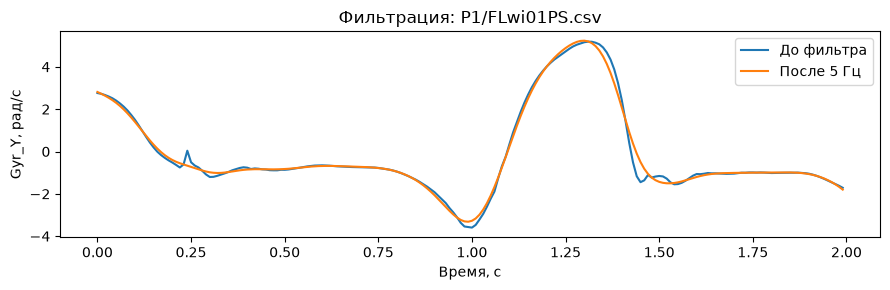

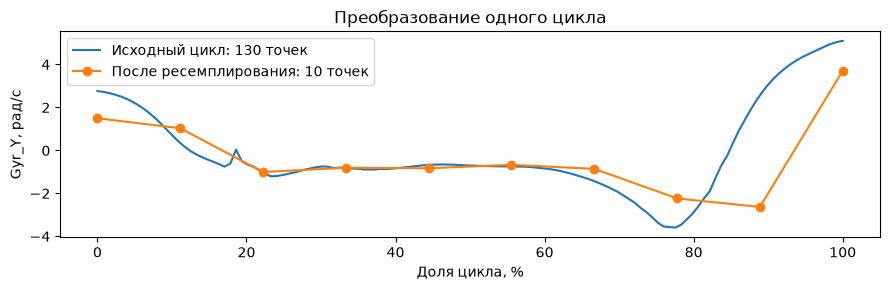

In [5]:
fig, ax = plt.subplots(figsize=(9, 3))
ax.plot(np.arange(len(signal_example["raw"])) / FS,
        signal_example["raw"], label="До фильтра")
ax.plot(np.arange(len(signal_example["filtered"])) / FS,
        signal_example["filtered"], label="После 5 Гц")
ax.set(xlabel="Время, с", ylabel="Gyr_Y, рад/с",
       title=f"Фильтрация: {signal_example['path']}")
ax.legend()
fig.tight_layout()
display(fig)
if SAVE_ARTIFACTS:
    fig.savefig(OUTPUT_DIR / "figures" / "01_filter_example.png", dpi=160)
    fig.savefig(OUTPUT_DIR / "figures" / "01_filter_example.svg")
plt.close(fig)

selected_cycle = cycles.iloc[0]
source_file = DATA_DIR / selected_cycle["path"]
source_data = pd.read_csv(source_file)["Gyr_Y"].to_numpy(dtype=float)
step_values = pd.read_csv(source_file)["Steps"].to_numpy()
bounds = np.flatnonzero(np.r_[True, step_values[1:] != step_values[:-1], True])
start, stop = bounds[int(selected_cycle["run"])], bounds[int(selected_cycle["run"]) + 1]
original_cycle = source_data[start:stop]
reduced_cycle = resample_poly(original_cycle, 10, len(original_cycle))
fig, ax = plt.subplots(figsize=(9, 3))
ax.plot(np.linspace(0, 100, len(original_cycle)), original_cycle,
        label=f"Исходный цикл: {len(original_cycle)} точек")
ax.plot(np.linspace(0, 100, 10), reduced_cycle, "o-", label="После ресемплирования: 10 точек")
ax.set(xlabel="Доля цикла, %", ylabel="Gyr_Y, рад/с",
       title="Преобразование одного цикла")
ax.legend()
fig.tight_layout()
display(fig)
if SAVE_ARTIFACTS:
    fig.savefig(OUTPUT_DIR / "figures" / "02_resampling_example.png", dpi=160)
    fig.savefig(OUTPUT_DIR / "figures" / "02_resampling_example.svg")
plt.close(fig)

In [6]:
display(Markdown(
    f"Фильтр сглаживает быстрые колебания, сохраняя ход сигнала на масштабе цикла. "
    f"Второй график показывает перевод **{len(original_cycle)} исходных точек** в 10. "
    f"До исключений найдено **{raw_cycle_count:,}** непрерывных сегментов `Steps`; "
    f"в статье приведено 9717 циклов. Разница составляет **{raw_cycle_count - 9717:+,}**. "
    "Это наблюдение само по себе не устанавливает причину расхождения: в статье "
    "не опубликован полный список включённых сегментов."
))

Фильтр сглаживает быстрые колебания, сохраняя ход сигнала на масштабе цикла. Второй график показывает перевод **130 исходных точек** в 10. До исключений найдено **9,783** непрерывных сегментов `Steps`; в статье приведено 9717 циклов. Разница составляет **+66**. Это наблюдение само по себе не устанавливает причину расхождения: в статье не опубликован полный список включённых сегментов.

### Состав классов после отбора

Здесь подсчитываются циклы, а не строки датчика. Коды 8/9 оставлены числовыми из-за противоречия в их названиях. Значение `Turn=2` не удаляет цикл: `Turn` не является меткой этой задачи.

,Код,Поверхность,Циклы после QC
0,1,Ровно,2935
1,2,Трава,1009
2,4,Лестница вверх,714
3,5,Лестница вниз,722
4,6,Подъём,940
5,7,Спуск,1043
6,8,Код 8,1450
7,9,Код 9,968


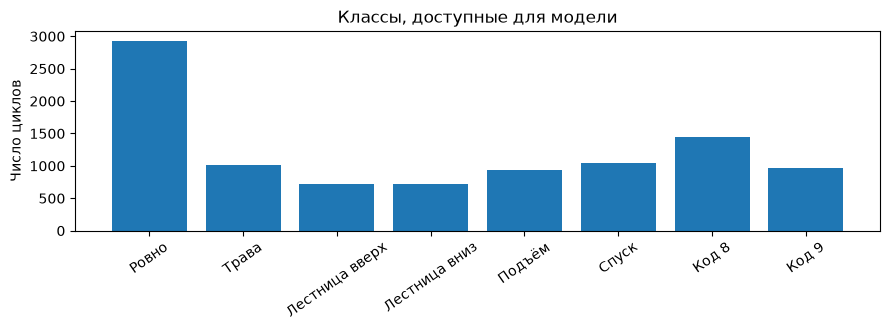

In [7]:
class_counts = cycles.groupby("terrain").size().reindex(TERRAIN_CODES, fill_value=0)
class_table = pd.DataFrame({"Код": TERRAIN_CODES,
                            "Поверхность": [TERRAIN_NAMES[code] for code in TERRAIN_CODES],
                            "Циклы после QC": class_counts.to_numpy()})
display(class_table)
fig, ax = plt.subplots(figsize=(9, 3.4))
ax.bar(class_table["Поверхность"], class_table["Циклы после QC"])
ax.set(ylabel="Число циклов", title="Классы, доступные для модели")
ax.tick_params(axis="x", labelrotation=35)
fig.tight_layout()
display(fig)
if SAVE_ARTIFACTS:
    fig.savefig(OUTPUT_DIR / "figures" / "03_class_balance.png", dpi=160)
    fig.savefig(OUTPUT_DIR / "figures" / "03_class_balance.svg")
plt.close(fig)

In [8]:
least_common = class_table.loc[class_table["Циклы после QC"].idxmin()]
most_common = class_table.loc[class_table["Циклы после QC"].idxmax()]
display(Markdown(
    f"После отбора осталось **{len(cycles):,} циклов**. Меньше всего циклов у "
    f"«{least_common['Поверхность']}» ({least_common['Циклы после QC']:,}), "
    f"больше всего у «{most_common['Поверхность']}» "
    f"({most_common['Циклы после QC']:,}). Неравный объём классов влияет на accuracy; "
    "поэтому ниже также показаны macro-F1, balanced accuracy и recall."
))

После отбора осталось **9,781 циклов**. Меньше всего циклов у «Лестница вверх» (714), больше всего у «Ровно» (2,935). Неравный объём классов влияет на accuracy; поэтому ниже также показаны macro-F1, balanced accuracy и recall.

### Сравнение числа циклов с таблицей 2 статьи

В статье указано 9717 циклов. Разница с текущим подсчётом показана по каждому коду. Для 8 и 9 числа статьи сопоставлены с метками маршрутов `UN` и `GV`, хотя их названия противоречат README набора. Файл P6 с `w0` не переименовывается в запись «без опоры» без подтверждения.

In [9]:
published_class_counts = {1: 2951, 2: 1011, 4: 700, 5: 710,
                          6: 939, 7: 1042, 8: 1418, 9: 946}
aid_counts = pd.crosstab(cycles["terrain"], cycles["aid"])
aid_counts = aid_counts.reindex(TERRAIN_CODES, fill_value=0)
table2 = pd.DataFrame({"код": TERRAIN_CODES,
                       "статья, циклы": [published_class_counts[c] for c in TERRAIN_CODES],
                       "локально после QC": class_counts.to_numpy()})
table2["разница"] = table2["локально после QC"] - table2["статья, циклы"]
table2 = table2.join(aid_counts.reset_index(drop=True))
display(table2)
print("Сумма таблицы 2:", sum(published_class_counts.values()))

,код,"статья, циклы",локально после QC,разница,w0,wi,wo
0,1,2951,2935,-16,24,1289,1622
1,2,1011,1009,-2,0,338,671
2,4,700,714,14,0,279,435
3,5,710,722,12,0,278,444
4,6,939,940,1,0,287,653
5,7,1042,1043,1,0,329,714
6,8,1418,1450,32,0,556,894
7,9,946,968,22,0,365,603


Сумма таблицы 2: 9717


In [10]:
largest_gap = table2.iloc[table2["разница"].abs().argmax()]
display(Markdown(
    f"Наибольшая абсолютная разница с таблицей 2 приходится на код "
    f"**{int(largest_gap['код'])}**: **{int(largest_gap['разница']):+,}** циклов. "
    "Причину нельзя установить по итоговым суммам: возможны различия в составлении "
    "окон, нумерации P7 и исключениях. Список исключённых путей сохранён ниже."
))

Наибольшая абсолютная разница с таблицей 2 приходится на код **8**: **+32** циклов. Причину нельзя установить по итоговым суммам: возможны различия в составлении окон, нумерации P7 и исключениях. Список исключённых путей сохранён ниже.

## 4. Разделение данных

CV делит циклы и может оставить одного человека в обучении и тесте. Совпадающие 300-мерные векторы удерживаются в одном фолде. Такой результат характеризует новые циклы знакомых участников.

LSO делит людей целиком на пять групп по четыре человека. Группы взяты из `LSOsplit.m` с исправлением опечаток; оба представления P7 входят во второй фолд. Буквально выполнить опубликованный скрипт нельзя: он разделяет P7 между обучением и тестом.

In [11]:
LSO_GROUPS = [
    ["P6", "P3", "P16", "P11"],
    ["P7", "P17", "P14", "P8"],
    ["P2", "P4", "P12", "P13"],
    ["P9", "P20", "P10", "P18"],
    ["P5", "P19", "P15", "P1"],
]
assert sorted(person for fold in LSO_GROUPS for person in fold) == sorted(physical_people)

fingerprints = np.array([hashlib.sha256(row.tobytes()).hexdigest() for row in X])
cv = StratifiedGroupKFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE)
cv_splits = list(cv.split(X, y, groups=fingerprints))
lso_splits = []
for held_out in LSO_GROUPS:
    test_mask = np.isin(physical_ids, held_out)
    train_indices = np.flatnonzero(~test_mask)
    test_indices = np.flatnonzero(test_mask)
    assert len(test_indices) > 0
    assert set(physical_ids[train_indices]).isdisjoint(physical_ids[test_indices])
    lso_splits.append((train_indices, test_indices))

split_rows = []
for scheme, splits in [("CV", cv_splits), ("LSO", lso_splits)]:
    for fold, (train_indices, test_indices) in enumerate(splits, start=1):
        assert set(fingerprints[train_indices]).isdisjoint(fingerprints[test_indices])
        train_people = sorted(set(physical_ids[train_indices]), key=lambda p: int(p[1:]))
        test_people = sorted(set(physical_ids[test_indices]), key=lambda p: int(p[1:]))
        split_rows.append({"Схема": scheme, "Fold": fold,
                           "Участники train": ", ".join(train_people),
                           "Участники test": ", ".join(test_people),
                           "Объектов train": len(train_indices),
                           "Объектов test": len(test_indices)})
split_table = pd.DataFrame(split_rows)
display(split_table)

,Схема,Fold,Участники train,Участники test,Объектов train,Объектов test
0,CV,1,"P1, P2, P3, P4, P5, P6, P7, P8, P9, P10, P11, ...","P1, P2, P3, P4, P5, P6, P7, P8, P9, P10, P11, ...",7824,1957
1,CV,2,"P1, P2, P3, P4, P5, P6, P7, P8, P9, P10, P11, ...","P1, P2, P3, P4, P5, P6, P7, P8, P9, P10, P11, ...",7825,1956
2,CV,3,"P1, P2, P3, P4, P5, P6, P7, P8, P9, P10, P11, ...","P1, P2, P3, P4, P5, P6, P7, P8, P9, P10, P11, ...",7826,1955
3,CV,4,"P1, P2, P3, P4, P5, P6, P7, P8, P9, P10, P11, ...","P1, P2, P3, P4, P5, P6, P7, P8, P9, P10, P11, ...",7825,1956
4,CV,5,"P1, P2, P3, P4, P5, P6, P7, P8, P9, P10, P11, ...","P1, P2, P3, P4, P5, P6, P7, P8, P9, P10, P11, ...",7824,1957
5,LSO,1,"P1, P2, P4, P5, P7, P8, P9, P10, P12, P13, P14...","P3, P6, P11, P16",7390,2391
6,LSO,2,"P1, P2, P3, P4, P5, P6, P9, P10, P11, P12, P13...","P7, P8, P14, P17",7482,2299
7,LSO,3,"P1, P3, P5, P6, P7, P8, P9, P10, P11, P14, P15...","P2, P4, P12, P13",7987,1794
8,LSO,4,"P1, P2, P3, P4, P5, P6, P7, P8, P11, P12, P13,...","P9, P10, P18, P20",7902,1879
9,LSO,5,"P2, P3, P4, P6, P7, P8, P9, P10, P11, P12, P13...","P1, P5, P15, P19",8363,1418


In [12]:
display(Markdown(
    "Для LSO пересечение физических участников и точных векторов между train и test "
    "проверено программно. У CV участники пересекаются по определению, но точные "
    "повторы векторов удерживаются вместе. Эти схемы измеряют разные задачи, "
    "поэтому более высокая CV accuracy не доказывает качество на новых людях."
))

Для LSO пересечение физических участников и точных векторов между train и test проверено программно. У CV участники пересекаются по определению, но точные повторы векторов удерживаются вместе. Эти схемы измеряют разные задачи, поэтому более высокая CV accuracy не доказывает качество на новых людях.

## 5. Модель и оценка

Random Forest использует 100 деревьев, `min_samples_leaf=1`, `max_features=7` и сбалансированные веса классов. Это близко к настройке `RF.m`, но веса и деревья в scikit-learn устроены иначе. Python seed зафиксирован; seed авторов неизвестен.

Для каждого фолда сохраняются предсказания, accuracy, macro-F1 и balanced accuracy. Со статьёй сравнивается средняя accuracy пяти фолдов.

In [13]:
MODEL_PARAMS = {"n_estimators": 100, "min_samples_leaf": 1,
                "max_features": 7, "class_weight": "balanced",
                "bootstrap": True, "n_jobs": -1, "random_state": RANDOM_STATE}

def fit_folds(experiment, labels, splits, label_order):
    fold_rows = []
    predictions = []
    for fold, (train_indices, test_indices) in enumerate(splits, start=1):
        model = RandomForestClassifier(**MODEL_PARAMS)
        model.fit(X[train_indices], labels[train_indices])
        predicted = model.predict(X[test_indices])
        true = labels[test_indices]
        fold_rows.append({"experiment": experiment, "fold": fold,
                          "test_people": ",".join(sorted(set(physical_ids[test_indices]))),
                          "train_cycles": len(train_indices),
                          "test_cycles": len(test_indices),
                          "accuracy": accuracy_score(true, predicted),
                          "macro_f1": f1_score(true, predicted,
                                               labels=label_order, average="macro",
                                               zero_division=0),
                          "balanced_accuracy": balanced_accuracy_score(true, predicted)})
        held_out = cycles.iloc[test_indices][[
            "participant", "recording_group", "path", "trial", "step", "run"
        ]].copy()
        held_out["experiment"] = experiment
        held_out["fold"] = fold
        held_out["true"] = true
        held_out["predicted"] = predicted
        predictions.append(held_out)
        print(experiment, "fold", fold,
              f"accuracy={fold_rows[-1]['accuracy']:.3f}",
              f"test={len(test_indices):,}")
    return pd.DataFrame(fold_rows), pd.concat(predictions, ignore_index=True)

def fold_summary(folds):
    mean = folds["accuracy"].mean()
    sd = folds["accuracy"].std(ddof=1)
    return {"mean_accuracy": mean, "sd_accuracy": sd,
            "mean_macro_f1": folds["macro_f1"].mean(),
            "mean_balanced_accuracy": folds["balanced_accuracy"].mean()}

def per_class_results(predictions, label_order):
    matrix = confusion_matrix(predictions["true"], predictions["predicted"],
                              labels=label_order)
    totals = matrix.sum(axis=1)
    recall = np.divide(np.diag(matrix), totals,
                       out=np.full(len(label_order), np.nan), where=totals > 0)
    classes = pd.DataFrame({"Код": label_order, "Циклов": totals,
                            "Recall": recall})
    return matrix, classes

def plot_confusion(predictions, label_order, title, filename):
    matrix, classes = per_class_results(predictions, label_order)
    row_total = matrix.sum(axis=1, keepdims=True)
    relative = np.divide(matrix, row_total,
                         out=np.zeros_like(matrix, dtype=float), where=row_total > 0)
    fig, ax = plt.subplots(figsize=(7.5, 6))
    image = ax.imshow(relative, vmin=0, vmax=1, cmap="Blues")
    for row in range(len(label_order)):
        for col in range(len(label_order)):
            ax.text(col, row, f"{relative[row, col]:.0%}", ha="center", va="center",
                    fontsize=8, color="white" if relative[row, col] > .55 else "black")
    ax.set_xticks(range(len(label_order)), labels=[str(c) for c in label_order])
    ax.set_yticks(range(len(label_order)), labels=[str(c) for c in label_order])
    ax.set(xlabel="Предсказанный код", ylabel="Истинный код", title=title)
    fig.colorbar(image, ax=ax, label="Доля внутри истинного класса")
    fig.tight_layout()
    display(fig)
    if SAVE_ARTIFACTS:
        fig.savefig(OUTPUT_DIR / "figures" / f"{filename}.png", dpi=160)
        fig.savefig(OUTPUT_DIR / "figures" / f"{filename}.svg")
    plt.close(fig)
    return matrix, classes

def describe_classes(classes, scheme):
    valid = classes.dropna(subset=["Recall"])
    best = valid.loc[valid["Recall"].idxmax()]
    worst = valid.loc[valid["Recall"].idxmin()]
    display(Markdown(
        f"В {scheme} наибольший recall у кода **{int(best['Код'])}** "
        f"({best['Recall']:.1%}), наименьший у кода **{int(worst['Код'])}** "
        f"({worst['Recall']:.1%}). Матрица показывает долю ошибок внутри каждого "
        "истинного класса; малый класс требует осторожной интерпретации."
    ))

### Восемь кодов: CV

Каждый фолд получает отдельную модель. Отличия от статьи включают реализацию леса, seed и исключение точного дубликата PS.

8_CV fold 1 accuracy=0.824 test=1,957


8_CV fold 2 accuracy=0.825 test=1,956


8_CV fold 3 accuracy=0.819 test=1,955


8_CV fold 4 accuracy=0.837 test=1,956


8_CV fold 5 accuracy=0.841 test=1,957


,experiment,fold,test_people,train_cycles,test_cycles,accuracy,macro_f1,balanced_accuracy
0,8_CV,1,"P1,P10,P11,P12,P13,P14,P15,P16,P17,P18,P19,P2,...",7824,1957,0.824221,0.831358,0.824973
1,8_CV,2,"P1,P10,P11,P12,P13,P14,P15,P16,P17,P18,P19,P2,...",7825,1956,0.824642,0.830980,0.825775
2,8_CV,3,"P1,P10,P11,P12,P13,P14,P15,P16,P17,P18,P19,P2,...",7826,1955,0.819437,0.824833,0.821992
3,8_CV,4,"P1,P10,P11,P12,P13,P14,P15,P16,P17,P18,P19,P2,...",7825,1956,0.836912,0.841016,0.839799
4,8_CV,5,"P1,P10,P11,P12,P13,P14,P15,P16,P17,P18,P19,P2,...",7824,1957,0.840572,0.849818,0.846645


,mean_accuracy,sd_accuracy,mean_macro_f1,mean_balanced_accuracy
0,0.829157,0.009078,0.835601,0.831837


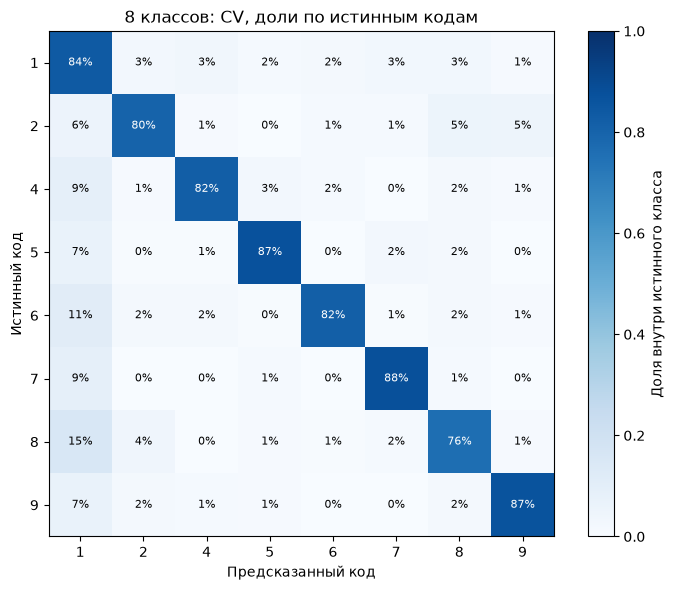

,Код,Циклов,Recall
0,1,2935,0.838842
1,2,1009,0.800793
2,4,714,0.822129
3,5,722,0.872576
4,6,940,0.819149
5,7,1043,0.876318
6,8,1450,0.759310
7,9,968,0.865702


В CV наибольший recall у кода **7** (87.6%), наименьший у кода **8** (75.9%). Матрица показывает долю ошибок внутри каждого истинного класса; малый класс требует осторожной интерпретации.

In [14]:
cv_folds, cv_predictions = fit_folds("8_CV", y, cv_splits, TERRAIN_CODES)
display(cv_folds)
cv_stats = fold_summary(cv_folds)
display(pd.DataFrame([cv_stats]))
cv_matrix, cv_classes = plot_confusion(cv_predictions, TERRAIN_CODES,
                                       "8 классов: CV, доли по истинным кодам",
                                       "04_confusion_8_cv")
display(cv_classes)
describe_classes(cv_classes, "CV")

### Восемь кодов: LSO

В каждом фолде тест состоит из четырёх новых людей. Оба представления P7 всегда находятся в одной части разделения.

8_LSO fold 1 accuracy=0.532 test=2,391


8_LSO fold 2 accuracy=0.550 test=2,299


8_LSO fold 3 accuracy=0.594 test=1,794


8_LSO fold 4 accuracy=0.578 test=1,879


8_LSO fold 5 accuracy=0.382 test=1,418


,experiment,fold,test_people,train_cycles,test_cycles,accuracy,macro_f1,balanced_accuracy
0,8_LSO,1,"P11,P16,P3,P6",7390,2391,0.531995,0.475265,0.499869
1,8_LSO,2,"P14,P17,P7,P8",7482,2299,0.550239,0.545100,0.543982
2,8_LSO,3,"P12,P13,P2,P4",7987,1794,0.593645,0.616883,0.608708
3,8_LSO,4,"P10,P18,P20,P9",7902,1879,0.577967,0.595922,0.588616
4,8_LSO,5,"P1,P15,P19,P5",8363,1418,0.382228,0.291990,0.298034


,mean_accuracy,sd_accuracy,mean_macro_f1,mean_balanced_accuracy
0,0.527215,0.084503,0.505032,0.507842


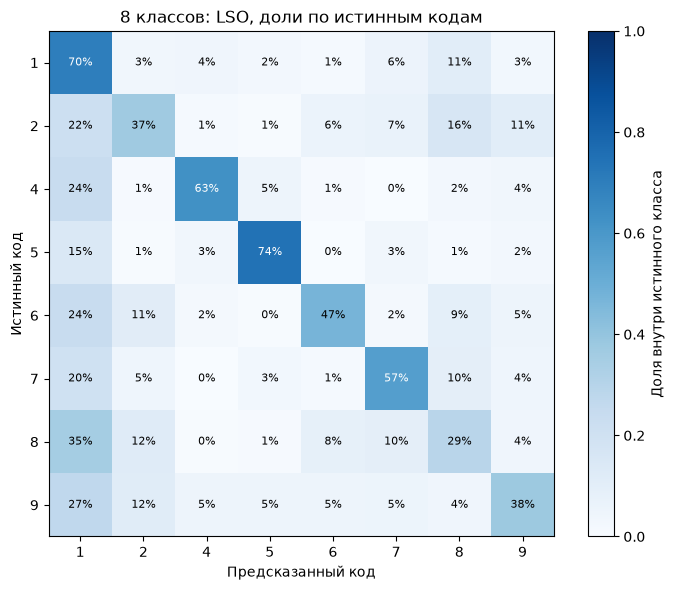

,Код,Циклов,Recall
0,1,2935,0.698467
1,2,1009,0.367691
2,4,714,0.628852
3,5,722,0.742382
4,6,940,0.472340
5,7,1043,0.568552
6,8,1450,0.291724
7,9,968,0.376033


В LSO наибольший recall у кода **5** (74.2%), наименьший у кода **8** (29.2%). Матрица показывает долю ошибок внутри каждого истинного класса; малый класс требует осторожной интерпретации.

In [15]:
lso_folds, lso_predictions = fit_folds("8_LSO", y, lso_splits, TERRAIN_CODES)
display(lso_folds)
lso_stats = fold_summary(lso_folds)
display(pd.DataFrame([lso_stats]))
lso_matrix, lso_classes = plot_confusion(lso_predictions, TERRAIN_CODES,
                                         "8 классов: LSO, доли по истинным кодам",
                                         "05_confusion_8_lso")
display(lso_classes)
describe_classes(lso_classes, "LSO")

In [16]:
cv_gap = 100 * (cv_stats["mean_accuracy"] - lso_stats["mean_accuracy"])
display(Markdown(
    f"Средняя CV accuracy составила **{cv_stats['mean_accuracy']:.1%}**, "
    f"LSO — **{lso_stats['mean_accuracy']:.1%}**. Разница **{cv_gap:+.2f} п.п.** "
    "Она показывает влияние смены тестовой задачи; причинное объяснение требует "
    "дополнительной проверки, поскольку CV и LSO имеют разный состав фолдов."
))

Средняя CV accuracy составила **82.9%**, LSO — **52.7%**. Разница **+30.19 п.п.** Она показывает влияние смены тестовой задачи; причинное объяснение требует дополнительной проверки, поскольку CV и LSO имеют разный состав фолдов.

## 6. Объединение кодов 2, 8 и 9

Статья объединяет траву и две сложные поверхности. Из-за противоречия в названиях 8/9 здесь выполняется только числовое преобразование `2, 8, 9 → 2`. Получается отдельная задача с шестью классами. Группы LSO сохраняются; CV строится заново для новых меток.

6_CV fold 1 accuracy=0.849 test=1,957


6_CV fold 2 accuracy=0.842 test=1,956


6_CV fold 3 accuracy=0.856 test=1,956


6_CV fold 4 accuracy=0.859 test=1,956


6_CV fold 5 accuracy=0.848 test=1,956


...

6_LSO fold 2 accuracy=0.588 test=2,299


6_LSO fold 3 accuracy=0.683 test=1,794


6_LSO fold 4 accuracy=0.696 test=1,879


6_LSO fold 5 accuracy=0.446 test=1,418


,Схема,mean_accuracy,sd_accuracy,mean_macro_f1,mean_balanced_accuracy
0,CV,0.850527,0.006907,0.851467,0.842092
1,LSO,0.604698,0.100171,0.586732,0.569695


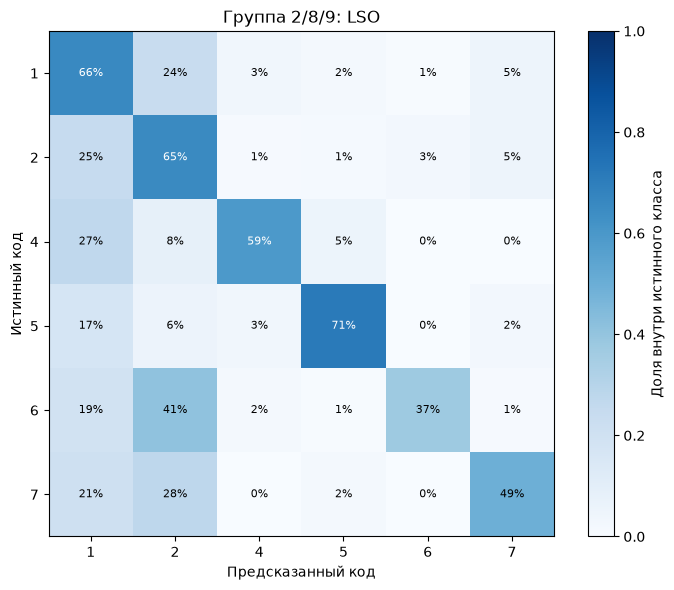

,Код,Циклов,Recall
0,1,2935,0.658603
1,2,3427,0.653925
2,4,714,0.592437
3,5,722,0.714681
4,6,940,0.371277
5,7,1043,0.493768


В LSO после объединения наибольший recall у кода **5** (71.5%), наименьший у кода **6** (37.1%). Матрица показывает долю ошибок внутри каждого истинного класса; малый класс требует осторожной интерпретации.

In [17]:
y_merged = np.where(np.isin(y, [2, 8, 9]), 2, y)
MERGED_CODES = [1, 2, 4, 5, 6, 7]
cv_merged = StratifiedGroupKFold(n_splits=5, shuffle=True,
                                 random_state=RANDOM_STATE)
merged_cv_splits = list(cv_merged.split(X, y_merged, groups=fingerprints))
for train_indices, test_indices in merged_cv_splits:
    assert set(fingerprints[train_indices]).isdisjoint(fingerprints[test_indices])

merged_cv_folds, merged_cv_predictions = fit_folds(
    "6_CV", y_merged, merged_cv_splits, MERGED_CODES)
merged_lso_folds, merged_lso_predictions = fit_folds(
    "6_LSO", y_merged, lso_splits, MERGED_CODES)
display(pd.DataFrame([
    {"Схема": "CV", **fold_summary(merged_cv_folds)},
    {"Схема": "LSO", **fold_summary(merged_lso_folds)},
]))
merged_lso_matrix, merged_lso_classes = plot_confusion(
    merged_lso_predictions, MERGED_CODES, "Группа 2/8/9: LSO",
    "06_confusion_6_lso")
display(merged_lso_classes)
describe_classes(merged_lso_classes, "LSO после объединения")

In [18]:
delta_lso = 100 * (fold_summary(merged_lso_folds)["mean_accuracy"]
                   - lso_stats["mean_accuracy"])
delta_cv = 100 * (fold_summary(merged_cv_folds)["mean_accuracy"]
                  - cv_stats["mean_accuracy"])
display(Markdown(
    f"После объединения средняя accuracy изменилась на **{delta_lso:+.2f} п.п.** "
    f"для LSO и **{delta_cv:+.2f} п.п.** для CV. Теперь различаются шесть "
    "категорий вместо восьми. Даже при росте метрики модель больше не обязана "
    "отличать траву от двух спорных кодов."
))

После объединения средняя accuracy изменилась на **+7.75 п.п.** для LSO и **+2.14 п.п.** для CV. Теперь различаются шесть категорий вместо восьми. Даже при росте метрики модель больше не обязана отличать траву от двух спорных кодов.

## 7. Сопоставление со статьёй

Таблица показывает среднюю accuracy пяти фолдов и разницу в процентных пунктах. Близкие числа не означают полного совпадения методики: опубликованный код содержит ошибки, а параметры финальной модели известны не полностью.

,Эксперимент,"Статья, %","Python, %","Разница, п.п."
0,"8 классов, LSO",56.89,52.72,-4.17
1,"8 классов, CV",83.64,82.92,-0.72
2,"6 классов, LSO",65.70,60.47,-5.23
3,"6 классов, CV",85.65,85.05,-0.60


,Эксперимент,Сопоставимость,Отличия
0,"8 классов, CV",частичная,"складка случайна по циклам, но без точных копи..."
1,"8 классов, LSO",частичная,исправлен P7 и опечатки групп; иные параметры ...
2,"6 классов, CV",частичная,другая цель; коды 8/9 объединены численно; sci...
3,"6 классов, LSO",частичная,другая цель; исправлены группы; scikit RF


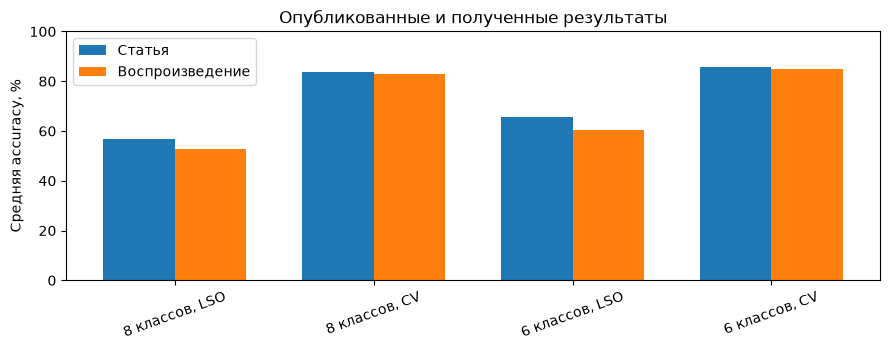

In [19]:
comparison = pd.DataFrame([
    {"Эксперимент": "8 классов, LSO", "Статья, %": 56.89,
     "Python, %": 100 * lso_stats["mean_accuracy"]},
    {"Эксперимент": "8 классов, CV", "Статья, %": 83.64,
     "Python, %": 100 * cv_stats["mean_accuracy"]},
    {"Эксперимент": "6 классов, LSO", "Статья, %": 65.70,
     "Python, %": 100 * fold_summary(merged_lso_folds)["mean_accuracy"]},
    {"Эксперимент": "6 классов, CV", "Статья, %": 85.65,
     "Python, %": 100 * fold_summary(merged_cv_folds)["mean_accuracy"]},
])
comparison["Разница, п.п."] = comparison["Python, %"] - comparison["Статья, %"]
display(comparison.round(2))
method_table = pd.DataFrame([
    {"Эксперимент": "8 классов, CV", "Сопоставимость": "частичная",
     "Отличия": "складка случайна по циклам, но без точных копий; scikit RF вместо TreeBagger"},
    {"Эксперимент": "8 классов, LSO", "Сопоставимость": "частичная",
     "Отличия": "исправлен P7 и опечатки групп; иные параметры финального леса"},
    {"Эксперимент": "6 классов, CV", "Сопоставимость": "частичная",
     "Отличия": "другая цель; коды 8/9 объединены численно; scikit RF"},
    {"Эксперимент": "6 классов, LSO", "Сопоставимость": "частичная",
     "Отличия": "другая цель; исправлены группы; scikit RF"},
])
display(method_table)
positions = np.arange(len(comparison))
fig, ax = plt.subplots(figsize=(9, 3.6))
ax.bar(positions - .18, comparison["Статья, %"], width=.36, label="Статья")
ax.bar(positions + .18, comparison["Python, %"], width=.36, label="Воспроизведение")
ax.set_xticks(positions, comparison["Эксперимент"], rotation=20)
ax.set(ylabel="Средняя accuracy, %", ylim=(0, 100),
       title="Опубликованные и полученные результаты")
ax.legend()
fig.tight_layout()
display(fig)
if SAVE_ARTIFACTS:
    fig.savefig(OUTPUT_DIR / "figures" / "07_article_comparison.png", dpi=160)
    fig.savefig(OUTPUT_DIR / "figures" / "07_article_comparison.svg")
plt.close(fig)

In [20]:
closest = comparison.iloc[comparison["Разница, п.п."].abs().argmin()]
largest = comparison.iloc[comparison["Разница, п.п."].abs().argmax()]
display(Markdown(
    f"Ближе всего к опубликованному значению оказался опыт "
    f"**{closest['Эксперимент']}** (разница {closest['Разница, п.п.']:+.2f} п.п.), "
    f"дальше всего — **{largest['Эксперимент']}** "
    f"({largest['Разница, п.п.']:+.2f} п.п.). Все четыре строки следует считать "
    "частичным методологическим воспроизведением, потому что параметры и разбиения "
    "авторов не восстановлены полностью."
))

Ближе всего к опубликованному значению оказался опыт **6 классов, CV** (разница -0.60 п.п.), дальше всего — **6 классов, LSO** (-5.23 п.п.). Все четыре строки следует считать частичным методологическим воспроизведением, потому что параметры и разбиения авторов не восстановлены полностью.

## 8. Leave-One-Participant-Out

Модель обучается на 19 людях и проверяется на оставшемся. P7_TT и P7_TF исключаются вместе. В таблице 4 статьи 21 строка и встречаются несоответствия с README набора, поэтому сопоставляется диапазон accuracy, а не строки с одинаковыми номерами участников.

8_LOPO fold 1 accuracy=0.330 test=827


8_LOPO fold 2 accuracy=0.569 test=559


8_LOPO fold 3 accuracy=0.425 test=454


8_LOPO fold 4 accuracy=0.490 test=447


8_LOPO fold 5 accuracy=0.504 test=234


...

8_LOPO fold 17 accuracy=0.406 test=212


8_LOPO fold 18 accuracy=0.363 test=113


8_LOPO fold 19 accuracy=0.230 test=217


8_LOPO fold 20 accuracy=0.234 test=192


,participant,test_cycles,accuracy,macro_f1
0,P1,827,0.330109,0.208940
1,P2,559,0.568873,0.529027
2,P3,454,0.425110,0.221554
3,P4,447,0.489933,0.503943
4,P5,234,0.504274,0.306650
5,P6,965,0.591710,0.590976
6,P7,1329,0.594432,0.518518
7,P8,527,0.557875,0.563320
8,P9,852,0.576291,0.564231
9,P10,722,0.668975,0.649256


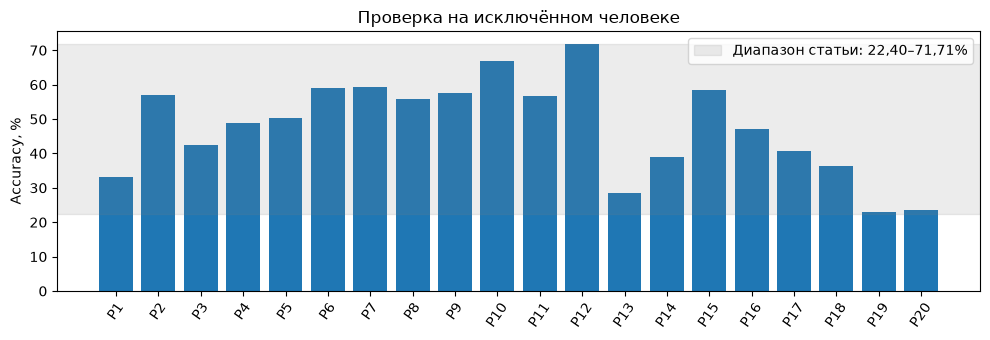

Диапазон LOPO в этой реализации: **23.0%–71.9%**. Авторы указали 22,40–71,71%. Близость диапазонов не доказывает совпадение отдельных участников или протокола.

In [21]:
if RUN_LOPO:
    lopo_splits = []
    for person in physical_people:
        test_indices = np.flatnonzero(physical_ids == person)
        train_indices = np.flatnonzero(physical_ids != person)
        assert set(physical_ids[train_indices]).isdisjoint(physical_ids[test_indices])
        lopo_splits.append((train_indices, test_indices))
    lopo_folds, lopo_predictions = fit_folds("8_LOPO", y, lopo_splits, TERRAIN_CODES)
    lopo_folds["participant"] = physical_people
    display(lopo_folds[["participant", "test_cycles", "accuracy", "macro_f1"]])
    fig, ax = plt.subplots(figsize=(10, 3.5))
    ax.bar(lopo_folds["participant"], 100 * lopo_folds["accuracy"])
    ax.axhspan(22.40, 71.71, color="grey", alpha=.15,
               label="Диапазон статьи: 22,40–71,71%")
    ax.set(ylabel="Accuracy, %", title="Проверка на исключённом человеке")
    ax.tick_params(axis="x", labelrotation=55)
    ax.legend()
    fig.tight_layout()
    display(fig)
    if SAVE_ARTIFACTS:
        fig.savefig(OUTPUT_DIR / "figures" / "08_lopo_by_person.png", dpi=160)
        fig.savefig(OUTPUT_DIR / "figures" / "08_lopo_by_person.svg")
    plt.close(fig)
    display(Markdown(
        f"Диапазон LOPO в этой реализации: "
        f"**{lopo_folds['accuracy'].min():.1%}–{lopo_folds['accuracy'].max():.1%}**. "
        "Авторы указали 22,40–71,71%. Близость диапазонов не доказывает "
        "совпадение отдельных участников или протокола."
    ))
else:
    lopo_folds = pd.DataFrame()
    lopo_predictions = pd.DataFrame()
    display(Markdown("LOPO выключен параметром `RUN_LOPO`."))

## 9. Сохранение результатов

При `SAVE_ARTIFACTS = True` сохраняются циклы, исключения, фолды, предсказания и матрицы ошибок. Отдельные модели каждого фолда не сохраняются: для воспроизведения нужны код, данные и конфигурация.

In [22]:
all_fold_tables = [cv_folds, lso_folds, merged_cv_folds, merged_lso_folds]
all_predictions = [cv_predictions, lso_predictions,
                   merged_cv_predictions, merged_lso_predictions]
if RUN_LOPO:
    all_fold_tables.append(lopo_folds)
    all_predictions.append(lopo_predictions)
fold_results = pd.concat(all_fold_tables, ignore_index=True)
predictions = pd.concat(all_predictions, ignore_index=True)
config = {
    "article_doi": "10.1371/journal.pone.0358882",
    "dataset_doi": manifest.get("dataset_doi"),
    "dataset_sha256": manifest.get("dataset_sha256"),
    "matlab_code_doi": "10.6084/m9.figshare.32805296.v3",
    "source_directory": str(DATA_DIR),
    "sampling_hz_assumed": FS,
    "filter": "butterworth_lowpass_order2_5Hz_filtfilt",
    "resampling": "scipy.signal.resample_poly_to_10_points",
    "features": "AVMFC_raw_and_per_recording_group_zscore",
    "number_of_features": X.shape[1],
    "model": MODEL_PARAMS,
    "physical_lso_groups": LSO_GROUPS,
    "random_state": RANDOM_STATE,
    "raw_step_segments": raw_cycle_count,
    "model_cycles": len(cycles),
    "run_lopo": RUN_LOPO,
    "date": datetime.now().astimezone().isoformat(timespec="seconds"),
    "python": platform.python_version(),
    "packages": {name: version(name) for name in
                 ["numpy", "pandas", "scipy", "scikit-learn", "matplotlib", "nbformat"]},
}
if SAVE_ARTIFACTS:
    cycles.to_csv(OUTPUT_DIR / "tables" / "cycles.csv", index=False)
    excluded_cycles.to_csv(OUTPUT_DIR / "tables" / "excluded_cycles.csv", index=False)
    class_table.to_csv(OUTPUT_DIR / "tables" / "class_balance.csv", index=False)
    table2.to_csv(OUTPUT_DIR / "tables" / "article_table2_comparison.csv", index=False)
    split_table.to_csv(OUTPUT_DIR / "tables" / "fold_membership.csv", index=False)
    fold_results.to_csv(OUTPUT_DIR / "tables" / "fold_results.csv", index=False)
    predictions.to_csv(OUTPUT_DIR / "tables" / "predictions.csv", index=False)
    comparison.to_csv(OUTPUT_DIR / "tables" / "article_comparison.csv", index=False)
    method_table.to_csv(OUTPUT_DIR / "tables" / "method_differences.csv", index=False)
    cv_classes.to_csv(OUTPUT_DIR / "tables" / "recall_8_cv.csv", index=False)
    lso_classes.to_csv(OUTPUT_DIR / "tables" / "recall_8_lso.csv", index=False)
    merged_lso_classes.to_csv(OUTPUT_DIR / "tables" / "recall_6_lso.csv", index=False)
    for name, matrix in [("confusion_8_cv", cv_matrix),
                         ("confusion_8_lso", lso_matrix),
                         ("confusion_6_lso", merged_lso_matrix)]:
        pd.DataFrame(matrix).to_csv(OUTPUT_DIR / "tables" / f"{name}.csv",
                                    index=False, header=False)
    (OUTPUT_DIR / "config.json").write_text(
        json.dumps(config, ensure_ascii=False, indent=2), encoding="utf-8")
    print("Результаты сохранены:", OUTPUT_DIR)
display(pd.Series(config["packages"], name="Версия").to_frame())

Результаты сохранены: ~/research-publication-data\artifacts\reports\reproduction_wassall_2026


,Версия
numpy,2.5.4
pandas,3.1.0
scipy,1.18.1
scikit-learn,1.9.1
matplotlib,3.11.2
nbformat,5.11.1


In [23]:
display(Markdown(
    f"Основные четыре опыта выполнены на **{len(cycles):,} отобранных циклах** "
    f"от **{len(physical_people)} физических участников**. "
    f"Средняя accuracy восьмиклассовой задачи: CV **{cv_stats['mean_accuracy']:.1%}**, "
    f"LSO **{lso_stats['mean_accuracy']:.1%}**. "
    "Python и MATLAB используют разные реализации леса; точные финальные "
    "параметры авторов неизвестны. LSO лучше описывает перенос на новых людей, "
    "но не подтверждает клиническую пригодность. Нумерация участников и "
    "значения кодов 8/9 остаются открытыми вопросами."
))

Основные четыре опыта выполнены на **9,781 отобранных циклах** от **20 физических участников**. Средняя accuracy восьмиклассовой задачи: CV **82.9%**, LSO **52.7%**. Python и MATLAB используют разные реализации леса; точные финальные параметры авторов неизвестны. LSO лучше описывает перенос на новых людей, но не подтверждает клиническую пригодность. Нумерация участников и значения кодов 8/9 остаются открытыми вопросами.